# **Importing Libararies**

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("Basic libraries imported successfully.")

Basic libraries imported successfully.


In [2]:
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

from sklearn.inspection import permutation_importance

print("Machine Learning libraries imported.")

Machine Learning libraries imported.


In [3]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from tensorflow.keras.regularizers import l2

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


# **Loading Dataset**

In [4]:
file_path = "/content/BreastCancerDataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (569, 33)


# **Dataset Analysis**

In [5]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [6]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Rows: 569
Columns: 33

Column names:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


In [9]:
missing_df = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing_df.sort_values(
    by="Missing Count",
    ascending=False
)

,Missing Count,Missing Percentage
Unnamed: 32,569,100.0
id,0,0.0
diagnosis,0,0.0
texture_mean,0,0.0
radius_mean,0,0.0
area_mean,0,0.0
smoothness_mean,0,0.0
compactness_mean,0,0.0
perimeter_mean,0,0.0
concave points_mean,0,0.0


# **Data Cleaning**

In [10]:
df_clean = df.copy()

# Remove identifier
df_clean.drop(
    columns=["id"],
    errors="ignore",
    inplace=True
)

# Remove completely empty columns
empty_columns = [
    col for col in df_clean.columns
    if df_clean[col].isna().all()
]

df_clean.drop(
    columns=empty_columns,
    inplace=True
)

print("Removed empty columns:", empty_columns)
print("Final dataset shape:", df_clean.shape)

Removed empty columns: ['Unnamed: 32']
Final dataset shape: (569, 31)


# **Feature and Target Selection**

In [11]:
print(
    df_clean["diagnosis"].value_counts()
)

print("\nPercentage:")
print(
    df_clean["diagnosis"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

diagnosis
B    357
M    212
Name: count, dtype: int64

Percentage:
diagnosis
B    62.74
M    37.26
Name: proportion, dtype: float64


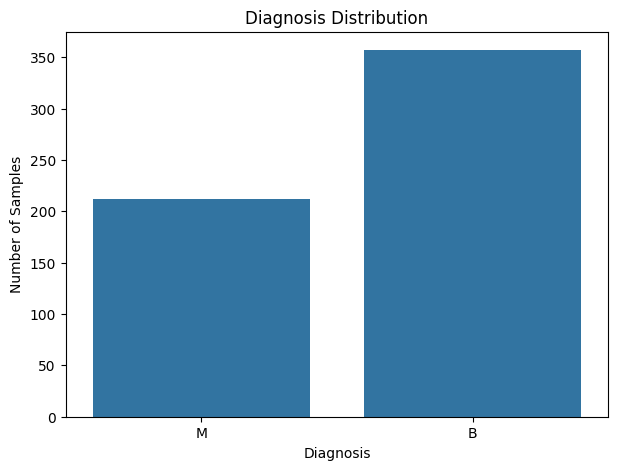

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="diagnosis"
)

plt.title("Diagnosis Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")

plt.show()

In [13]:
df_clean["diagnosis"] = df_clean["diagnosis"].map({
    "B": 0,
    "M": 1
})

print(df_clean["diagnosis"].value_counts())

diagnosis
0    357
1    212
Name: count, dtype: int64


In [14]:
X = df_clean.drop(
    columns=["diagnosis"]
)

y = df_clean["diagnosis"]

print("Feature matrix:", X.shape)
print("Target:", y.shape)

Feature matrix: (569, 30)
Target: (569,)


# **Exploratory Data Analysis**

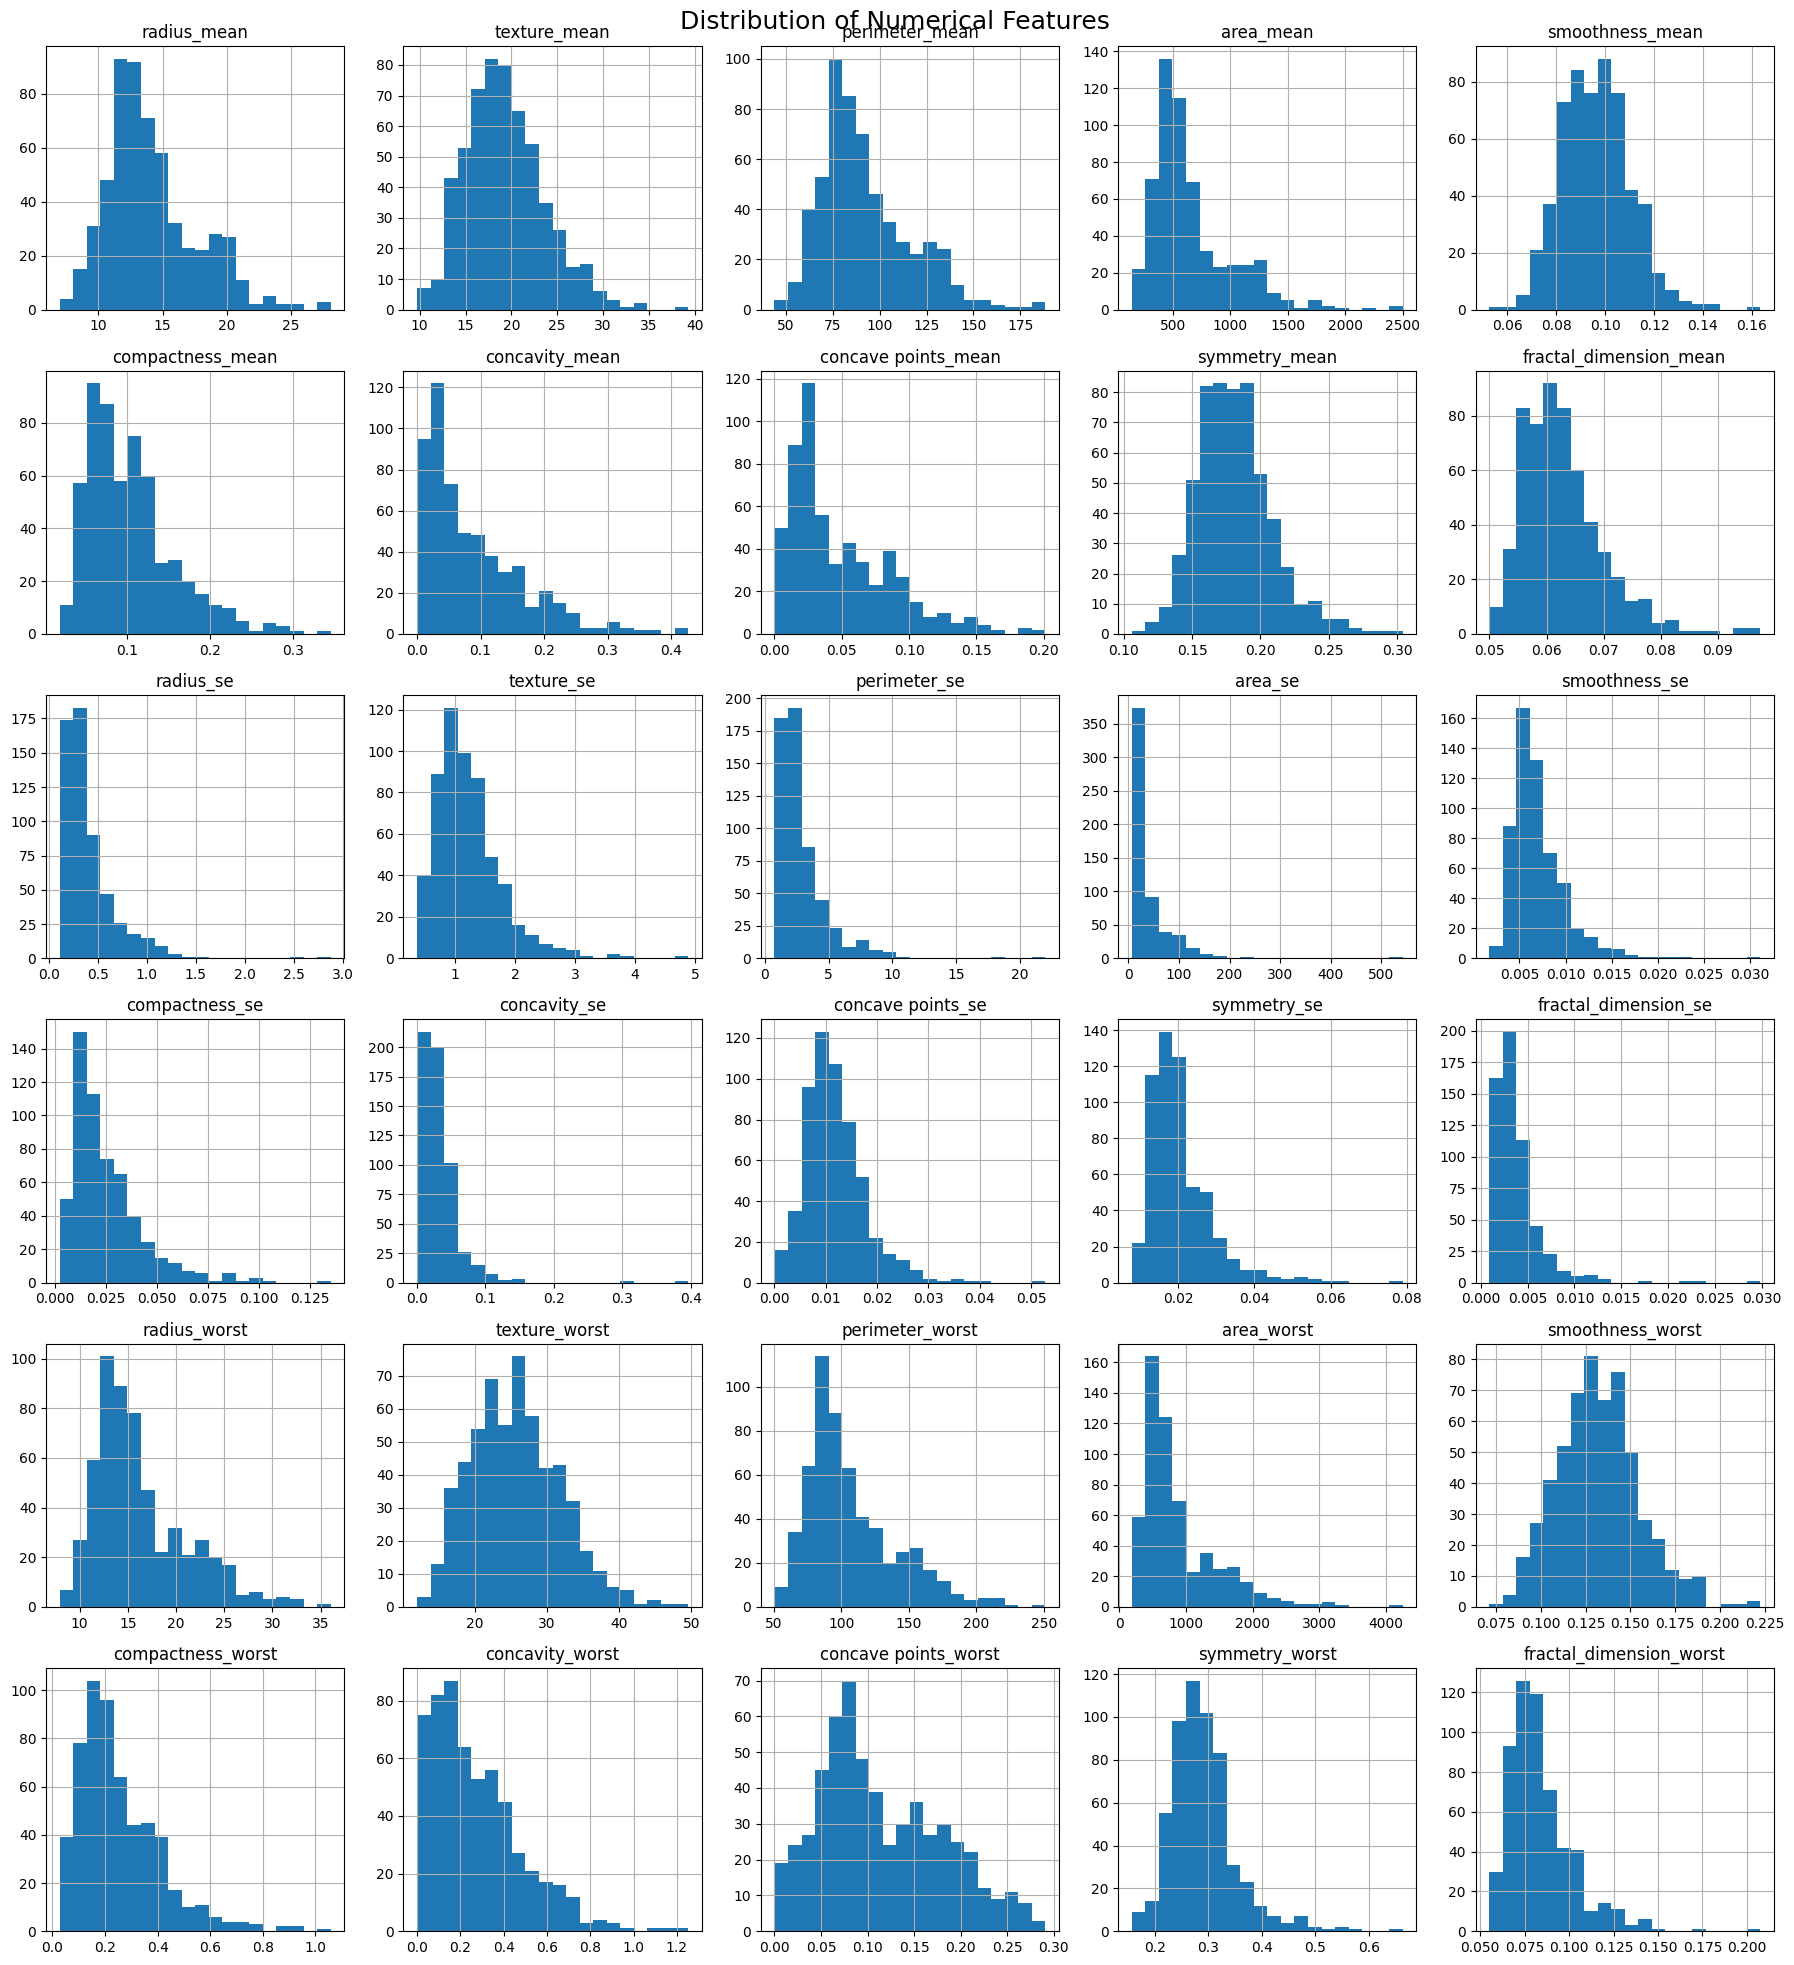

In [16]:
X.hist(
    figsize=(18, 20),
    bins=20
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=18
)

plt.tight_layout()
plt.show()

# **Train Test Split**

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 455
Testing samples: 114


# **Cross-Validation Configuration**

In [18]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# **ML Candidate Models**

In [19]:
ml_models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=42
        ))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            probability=True,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
}

print("ML models created successfully.")

for name in ml_models:
    print("-", name)

ML models created successfully.
- Logistic Regression
- SVM
- Random Forest
- Extra Trees
- Gradient Boosting


# **Train ML Models**

In [20]:
trained_ml_models = {}

for name, model in ml_models.items():

    print(f"Training {name}...")

    model.fit(
        X_train,
        y_train
    )

    trained_ml_models[name] = model

print("\nAll ML models trained successfully.")

Training Logistic Regression...
Training SVM...
Training Random Forest...
Training Extra Trees...
Training Gradient Boosting...

All ML models trained successfully.


# **Evaluate ML Models**

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

ml_cv_results = []

for name, model in ml_models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    ml_cv_results.append({
        "Model": name,
        "Mean ROC-AUC": scores.mean(),
        "Std ROC-AUC": scores.std()
    })

    print(
        f"{name}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

Logistic Regression: 0.9958 ± 0.0047
SVM: 0.9949 ± 0.0050
Random Forest: 0.9889 ± 0.0070
Extra Trees: 0.9916 ± 0.0058
Gradient Boosting: 0.9908 ± 0.0055


# **ML Model Comparison**

In [22]:
ml_results_df = pd.DataFrame(
    ml_cv_results
)

ml_results_df = ml_results_df.sort_values(
    by="Mean ROC-AUC",
    ascending=False
)

ml_results_df

,Model,Mean ROC-AUC,Std ROC-AUC
0,Logistic Regression,0.995769,0.004666
1,SVM,0.994943,0.004964
3,Extra Trees,0.991589,0.005773
4,Gradient Boosting,0.990815,0.005523
2,Random Forest,0.988854,0.006954


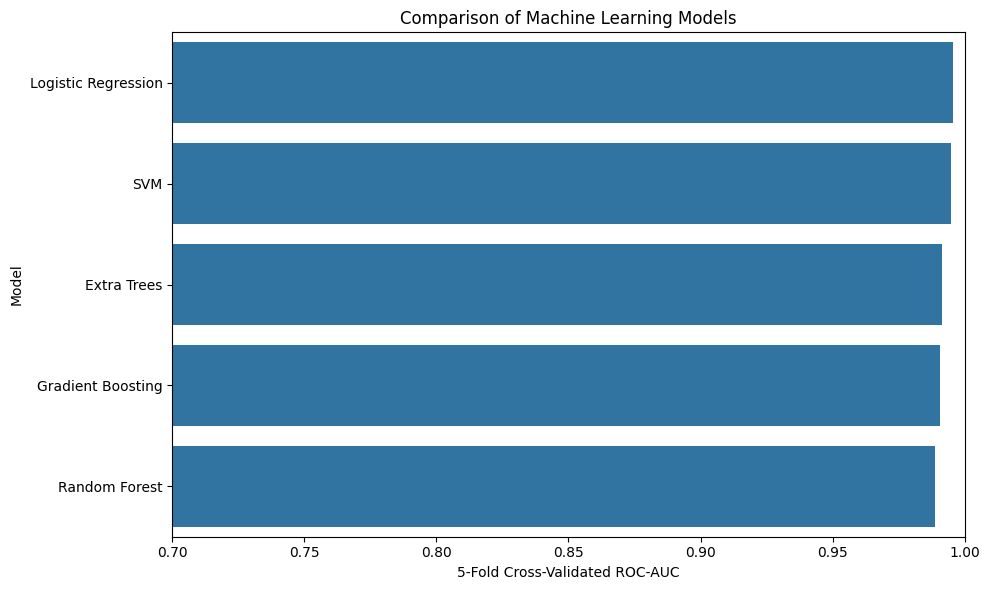

In [23]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=ml_results_df,
    x="Mean ROC-AUC",
    y="Model"
)

plt.title(
    "Comparison of Machine Learning Models"
)

plt.xlabel(
    "5-Fold Cross-Validated ROC-AUC"
)

plt.ylabel("Model")

plt.xlim(0.70, 1.00)

plt.tight_layout()
plt.show()

# **Selecting Best ML Model**

In [24]:
best_ml_name = ml_results_df.iloc[0]["Model"]

best_ml_model = trained_ml_models[
    best_ml_name
]

print("=" * 60)
print("BEST MACHINE LEARNING MODEL")
print("=" * 60)

print("Model:", best_ml_name)

print(
    "Mean CV ROC-AUC:",
    round(
        ml_results_df.iloc[0]["Mean ROC-AUC"],
        4
    )
)

print("=" * 60)

BEST MACHINE LEARNING MODEL
Model: Logistic Regression
Mean CV ROC-AUC: 0.9958


# **Prepare Data for Deep Learning**

In [25]:
scaler_dl = StandardScaler()

X_train_scaled = scaler_dl.fit_transform(
    X_train
)

X_test_scaled = scaler_dl.transform(
    X_test
)

print(
    "Training data shape:",
    X_train_scaled.shape
)

print(
    "Testing data shape:",
    X_test_scaled.shape
)

Training data shape: (455, 30)
Testing data shape: (114, 30)


# **Building Deep Learning ANN**

In [26]:
import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.regularizers import l2

dl_model = Sequential([

    Dense(
        32,
        activation="relu",
        input_shape=(X_train_scaled.shape[1],),
        kernel_regularizer=l2(0.001)
    ),

    BatchNormalization(),

    Dropout(0.30),

    Dense(
        16,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.20),

    Dense(
        8,
        activation="relu"
    ),

    Dense(
        1,
        activation="sigmoid"
    )
])

dl_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,793 (7.00 KB)

 Trainable params: 1,729 (6.75 KB)

 Non-trainable params: 64 (256.00 B)

# **Compiling ANN**

In [27]:
dl_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",

        tf.keras.metrics.AUC(
            name="auc"
        ),

        tf.keras.metrics.Precision(
            name="precision"
        ),

        tf.keras.metrics.Recall(
            name="recall"
        )
    ]
)

print("ANN compiled successfully.")

ANN compiled successfully.


In [28]:
dl_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",

        tf.keras.metrics.AUC(
            name="auc"
        ),

        tf.keras.metrics.Precision(
            name="precision"
        ),

        tf.keras.metrics.Recall(
            name="recall"
        )
    ]
)

print("ANN compiled successfully.")

ANN compiled successfully.


# **Training Deep Learning Model**

In [30]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=5,
    min_lr=0.0001
)

history = dl_model.fit(

    X_train_scaled,

    y_train,

    validation_split=0.20,

    epochs=10,

    batch_size=16,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 9s 200ms/step - accuracy: 0.5797 - auc: 0.5517 - loss: 0.7711 - precision: 0.4519 - recall: 0.4357 - val_accuracy: 0.7582 - val_auc: 0.7301 - val_loss: 0.6481 - val_precision: 0.7000 - val_recall: 0.4667 - learning_rate: 0.0010
Epoch 2/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8187 - auc: 0.8629 - loss: 0.5304 - precision: 0.7984 - recall: 0.7071 - val_accuracy: 0.8791 - val_auc: 0.9426 - val_loss: 0.4957 - val_precision: 0.8800 - val_recall: 0.7333 - learning_rate: 0.0010
Epoch 3/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8654 - auc: 0.9426 - loss: 0.4066 - precision: 0.8824 - recall: 0.7500 - val_accuracy: 0.9341 - val_auc: 0.9716 - val_loss: 0.3886 - val_precision: 0.9615 - val_recall: 0.8333 - learning_rate: 0.0010
Epoch 4/10
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9093 - auc: 0.9745 - loss: 0.3323 - precision: 0.9147 - recall: 0.8429 - val_accuracy: 0.9341 - val_auc: 0.9762 - val_loss: 0.3125 - val_preci

**ANN Training Accuracy**

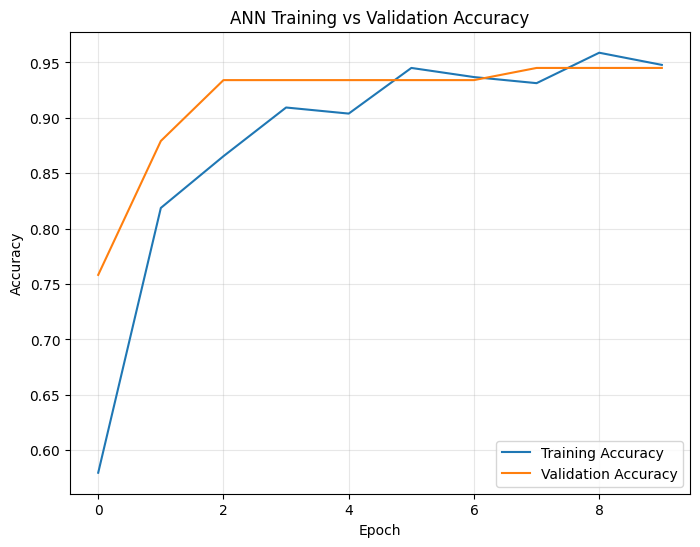

In [31]:
plt.figure(figsize=(8, 6))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "ANN Training vs Validation Accuracy"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

**ANN Training Loss**

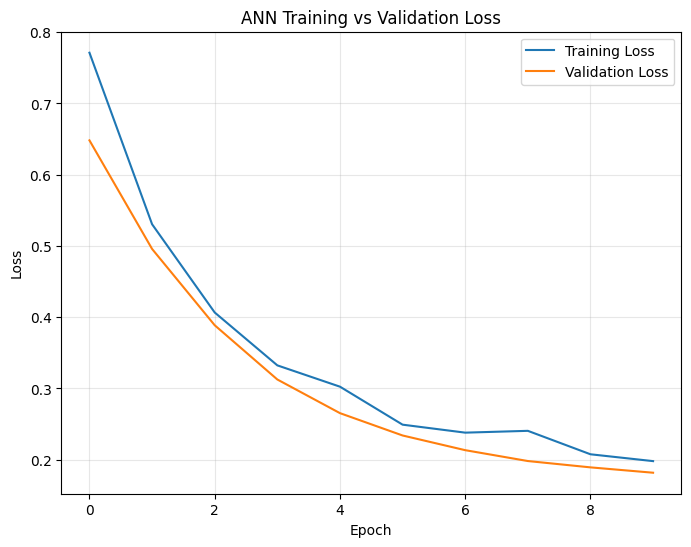

In [32]:
plt.figure(figsize=(8, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ANN Training vs Validation Loss"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

**ANN Training ROC-AUC**

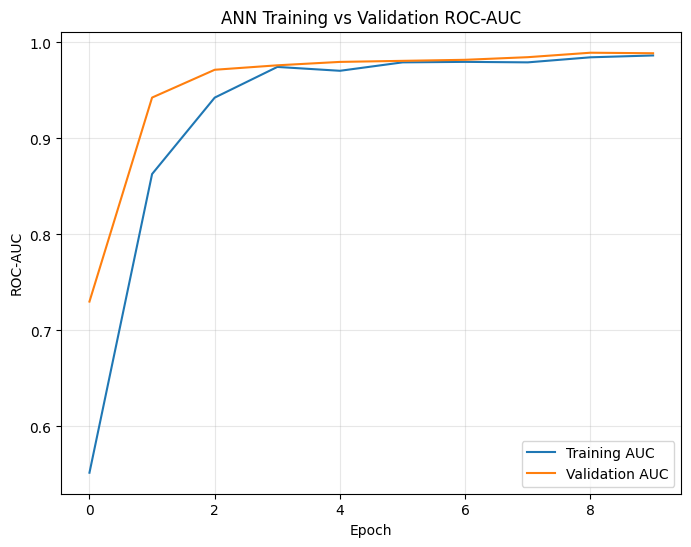

In [33]:
plt.figure(figsize=(8, 6))

plt.plot(
    history.history["auc"],
    label="Training AUC"
)

plt.plot(
    history.history["val_auc"],
    label="Validation AUC"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")

plt.title(
    "ANN Training vs Validation ROC-AUC"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

# **Generate ML Predictions**

In [34]:
ml_pred = best_ml_model.predict(
    X_test
)

ml_prob = best_ml_model.predict_proba(
    X_test
)[:, 1]

print("ML predictions generated.")

ML predictions generated.


# **Generate ANN Predictions**

In [35]:
dl_prob = dl_model.predict(
    X_test_scaled,
    verbose=0
).ravel()

dl_pred = (
    dl_prob >= 0.5
).astype(int)

print("ANN predictions generated.")

ANN predictions generated.


# **Model Evaluation Function**

In [36]:
def evaluate_model(
    model_name,
    y_true,
    y_pred,
    y_probability
):

    return {

        "Model": model_name,

        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "Precision": precision_score(
            y_true,
            y_pred
        ),

        "Recall": recall_score(
            y_true,
            y_pred
        ),

        "F1 Score": f1_score(
            y_true,
            y_pred
        ),

        "ROC-AUC": roc_auc_score(
            y_true,
            y_probability
        ),

        "PR-AUC": average_precision_score(
            y_true,
            y_probability
        )
    }

# **ML vs Deep Learning Comparison**

In [37]:
comparison_results = []

# Best ML model
comparison_results.append(
    evaluate_model(
        f"ML - {best_ml_name}",
        y_test,
        ml_pred,
        ml_prob
    )
)

# Deep Learning model
comparison_results.append(
    evaluate_model(
        "Deep Learning ANN",
        y_test,
        dl_pred,
        dl_prob
    )
)

comparison_df = pd.DataFrame(
    comparison_results
)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,ML - Logistic Regression,0.964912,0.975000,0.928571,0.95122,0.996032,0.994274
1,Deep Learning ANN,0.947368,0.973684,0.880952,0.92500,0.991733,0.985203


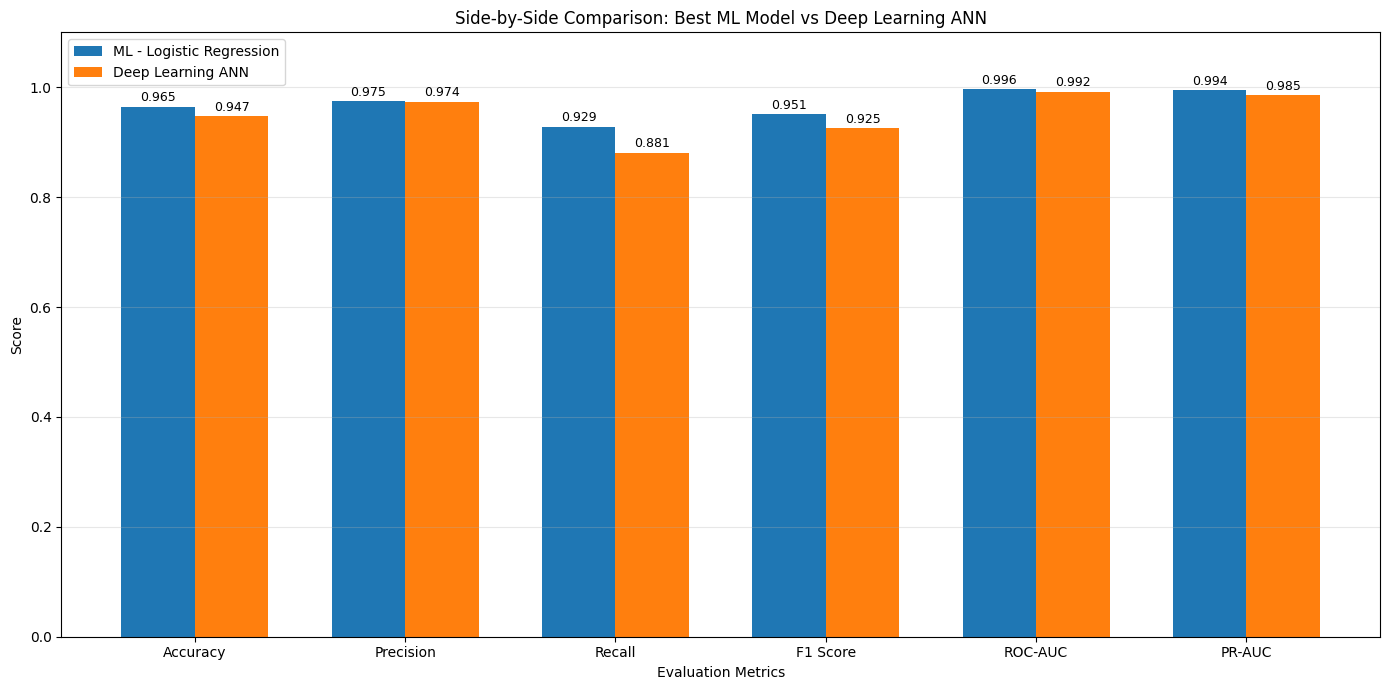

In [38]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "PR-AUC"
]

x = np.arange(len(metrics))
width = 0.35

ml_scores = comparison_df.iloc[0][metrics].values
dl_scores = comparison_df.iloc[1][metrics].values


plt.figure(figsize=(14, 7))

plt.bar(
    x - width / 2,
    ml_scores,
    width,
    label=f"ML - {best_ml_name}"
)

plt.bar(
    x + width / 2,
    dl_scores,
    width,
    label="Deep Learning ANN"
)


# Add values above bars

for i, value in enumerate(ml_scores):

    plt.text(
        i - width / 2,
        value + 0.01,
        f"{value:.3f}",
        ha="center",
        fontsize=9
    )


for i, value in enumerate(dl_scores):

    plt.text(
        i + width / 2,
        value + 0.01,
        f"{value:.3f}",
        ha="center",
        fontsize=9
    )


plt.xticks(
    x,
    metrics
)

plt.ylabel("Score")

plt.xlabel("Evaluation Metrics")

plt.title(
    "Side-by-Side Comparison: Best ML Model vs Deep Learning ANN"
)

plt.ylim(
    0,
    1.10
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

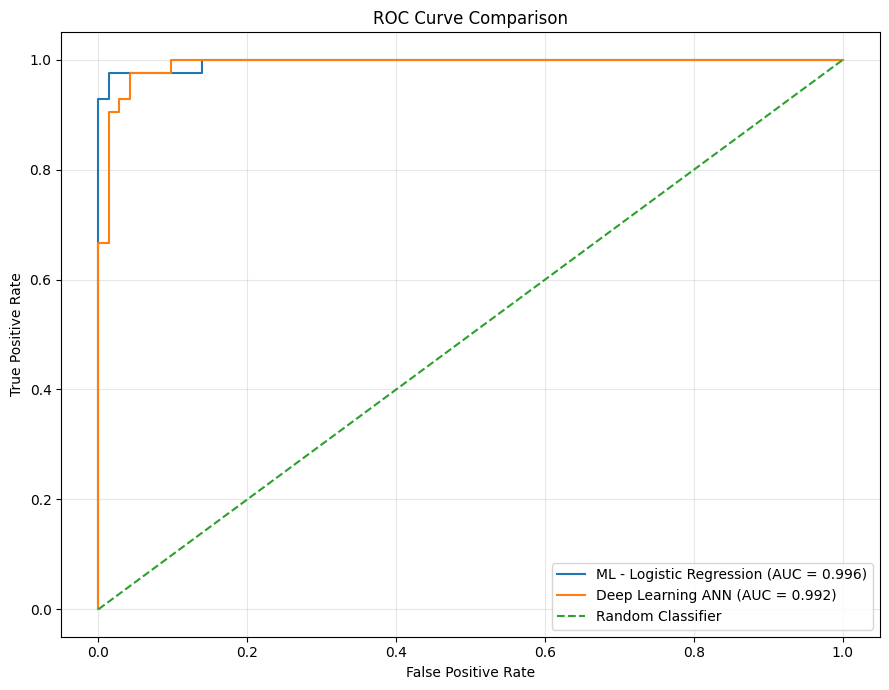

In [39]:
from sklearn.metrics import roc_curve

ml_fpr, ml_tpr, _ = roc_curve(
    y_test,
    ml_prob
)

dl_fpr, dl_tpr, _ = roc_curve(
    y_test,
    dl_prob
)


plt.figure(figsize=(9, 7))

plt.plot(
    ml_fpr,
    ml_tpr,
    label=f"ML - {best_ml_name} "
          f"(AUC = {roc_auc_score(y_test, ml_prob):.3f})"
)

plt.plot(
    dl_fpr,
    dl_tpr,
    label=f"Deep Learning ANN "
          f"(AUC = {roc_auc_score(y_test, dl_prob):.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve Comparison"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

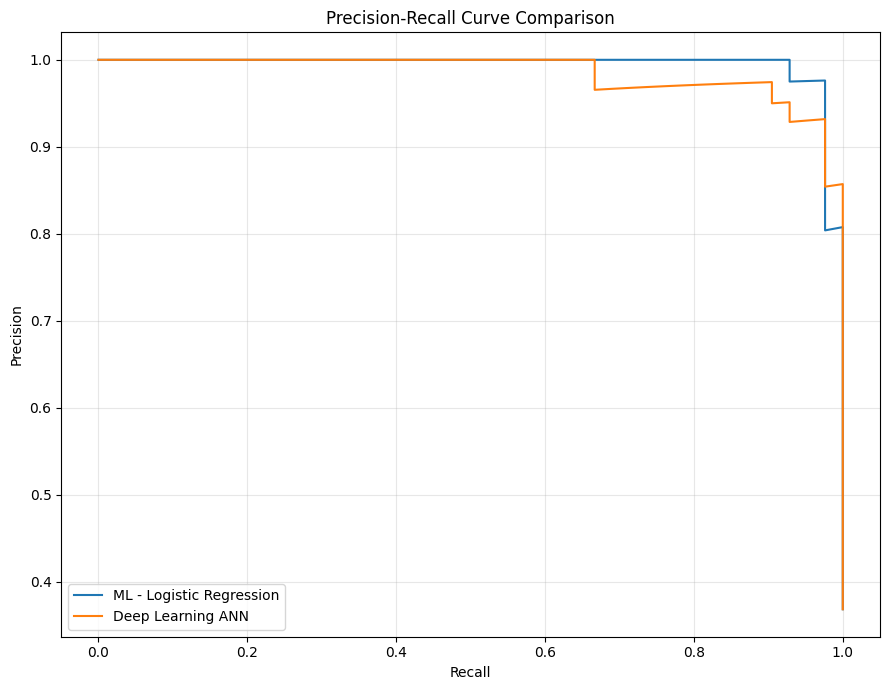

In [40]:
from sklearn.metrics import precision_recall_curve

ml_precision, ml_recall, _ = precision_recall_curve(
    y_test,
    ml_prob
)

dl_precision, dl_recall, _ = precision_recall_curve(
    y_test,
    dl_prob
)


plt.figure(figsize=(9, 7))

plt.plot(
    ml_recall,
    ml_precision,
    label=f"ML - {best_ml_name}"
)

plt.plot(
    dl_recall,
    dl_precision,
    label="Deep Learning ANN"
)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title(
    "Precision-Recall Curve Comparison"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [41]:
from sklearn.metrics import classification_report

print("=" * 65)
print(f"BEST ML MODEL — {best_ml_name}")
print("=" * 65)

print(
    classification_report(
        y_test,
        ml_pred,
        target_names=[
            "Benign",
            "Malignant"
        ]
    )
)


print("\n")


print("=" * 65)
print("DEEP LEARNING ANN")
print("=" * 65)

print(
    classification_report(
        y_test,
        dl_pred,
        target_names=[
            "Benign",
            "Malignant"
        ]
    )
)

BEST ML MODEL — Logistic Regression
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



DEEP LEARNING ANN
              precision    recall  f1-score   support

      Benign       0.93      0.99      0.96        72
   Malignant       0.97      0.88      0.93        42

    accuracy                           0.95       114
   macro avg       0.95      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114



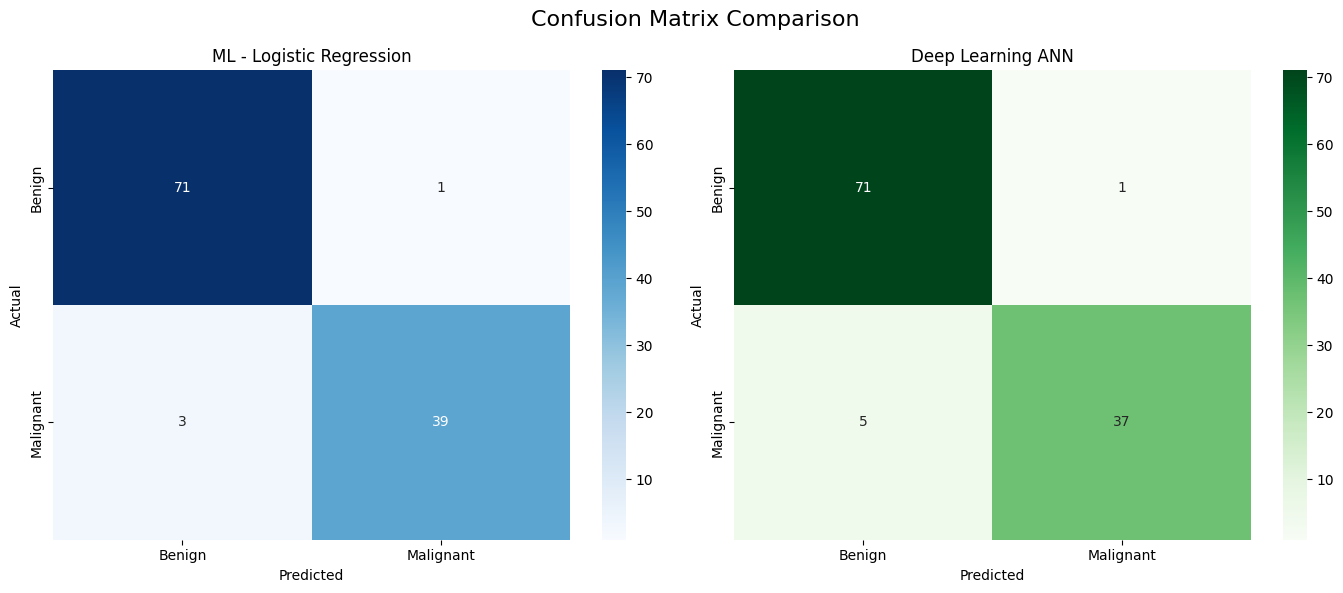

In [42]:
from sklearn.metrics import confusion_matrix

cm_ml = confusion_matrix(
    y_test,
    ml_pred
)

cm_dl = confusion_matrix(
    y_test,
    dl_pred
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6)
)


# ML Confusion Matrix

sns.heatmap(
    cm_ml,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Benign",
        "Malignant"
    ],
    yticklabels=[
        "Benign",
        "Malignant"
    ],
    ax=axes[0]
)

axes[0].set_title(
    f"ML - {best_ml_name}"
)

axes[0].set_xlabel(
    "Predicted"
)

axes[0].set_ylabel(
    "Actual"
)


# Deep Learning Confusion Matrix

sns.heatmap(
    cm_dl,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=[
        "Benign",
        "Malignant"
    ],
    yticklabels=[
        "Benign",
        "Malignant"
    ],
    ax=axes[1]
)

axes[1].set_title(
    "Deep Learning ANN"
)

axes[1].set_xlabel(
    "Predicted"
)

axes[1].set_ylabel(
    "Actual"
)


plt.suptitle(
    "Confusion Matrix Comparison",
    fontsize=16
)

plt.tight_layout()

plt.show()

In [43]:
final_comparison = comparison_df.copy()

final_comparison = final_comparison.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

final_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,ML - Logistic Regression,0.964912,0.975000,0.928571,0.95122,0.996032,0.994274
1,Deep Learning ANN,0.947368,0.973684,0.880952,0.92500,0.991733,0.985203


In [44]:
comparison_display = final_comparison.copy()

comparison_display[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ]
].round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,ML - Logistic Regression,0.9649,0.9750,0.9286,0.9512,0.9960,0.9943
1,Deep Learning ANN,0.9474,0.9737,0.8810,0.9250,0.9917,0.9852


# **Determine Overall Best Model**

In [45]:
winner_index = comparison_df[
    "ROC-AUC"
].idxmax()

winner = comparison_df.loc[
    winner_index
]

print("=" * 70)
print("FINAL MODEL SELECTION")
print("=" * 70)

print(
    f"Best Performing Approach: "
    f"{winner['Model']}"
)

print(
    f"\nAccuracy : "
    f"{winner['Accuracy']:.4f}"
)

print(
    f"Precision: "
    f"{winner['Precision']:.4f}"
)

print(
    f"Recall   : "
    f"{winner['Recall']:.4f}"
)

print(
    f"F1 Score : "
    f"{winner['F1 Score']:.4f}"
)

print(
    f"ROC-AUC  : "
    f"{winner['ROC-AUC']:.4f}"
)

print(
    f"PR-AUC   : "
    f"{winner['PR-AUC']:.4f}"
)

print("=" * 70)

FINAL MODEL SELECTION
Best Performing Approach: ML - Logistic Regression

Accuracy : 0.9649
Precision: 0.9750
Recall   : 0.9286
F1 Score : 0.9512
ROC-AUC  : 0.9960
PR-AUC   : 0.9943


# **Feature Importance for Best ML Model**

In [46]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    best_ml_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)


feature_importance = pd.DataFrame({

    "Feature": X_test.columns,

    "Importance":
        perm_result.importances_mean,

    "Std":
        perm_result.importances_std

})


feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)


feature_importance.head(20)

,Feature,Importance,Std
28,symmetry_worst,0.010196,0.002648
21,texture_worst,0.010053,0.004923
26,concavity_worst,0.007705,0.002513
27,concave points_worst,0.003020,0.001550
7,concave points_mean,0.002965,0.002253
6,concavity_mean,0.002756,0.001773
20,radius_worst,0.001995,0.001970
23,area_worst,0.001477,0.001901
11,texture_se,0.001433,0.000838
22,perimeter_worst,0.001400,0.001626


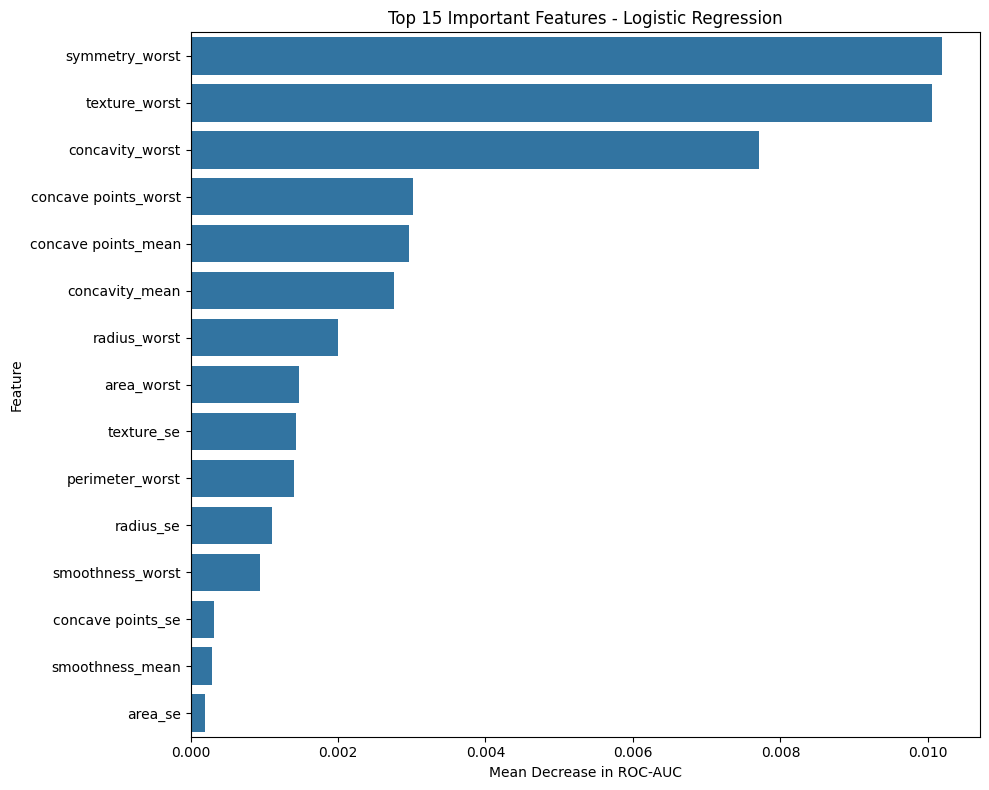

In [47]:
top_features = feature_importance.head(15)


plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title(
    f"Top 15 Important Features - {best_ml_name}"
)

plt.xlabel(
    "Mean Decrease in ROC-AUC"
)

plt.ylabel(
    "Feature"
)

plt.tight_layout()

plt.show()

# **Final Project Summary**

In [49]:
print("=" * 75)
print("BREAST CANCER DETECTION — FINAL PROJECT SUMMARY")
print("=" * 75)

print("\nDATASET")
print("-" * 75)

print(
    f"Training samples : {len(X_train)}"
)

print(
    f"Testing samples  : {len(X_test)}"
)

print(
    f"Number of features: {X.shape[1]}"
)


print("\nMACHINE LEARNING")
print("-" * 75)

print(
    f"Best ML Model: {best_ml_name}"
)

print(
    f"CV ROC-AUC: "
    f"{ml_results_df.iloc[0]['Mean ROC-AUC']:.4f}"
)


print("\nDEEP LEARNING")
print("-" * 75)

print(
    "Model: Regularized Artificial Neural Network"
)

print(
    f"Test ROC-AUC: "
    f"{comparison_df.loc[
        comparison_df['Model'] == 'Deep Learning ANN',
        'ROC-AUC'
    ].iloc[0]:.4f}"
)


print("\nFINAL COMPARISON")
print("-" * 75)

print(
    f"Overall Winner: "
    f"{winner['Model']}"
)


print(
    f"Winner Accuracy: "
    f"{winner['Accuracy']:.4f}"
)

print(
    f"Winner Precision: "
    f"{winner['Precision']:.4f}"
)

print(
    f"Winner Recall: "
    f"{winner['Recall']:.4f}"
)

print(
    f"Winner F1 Score: "
    f"{winner['F1 Score']:.4f}"
)

print(
    f"Winner ROC-AUC: "
    f"{winner['ROC-AUC']:.4f}"
)

print(
    f"Winner PR-AUC: "
    f"{winner['PR-AUC']:.4f}"
)


print("\nEXPLAINABLE AI")
print("-" * 75)

print(
    "Permutation Feature Importance: Applied"
)

print("=" * 75)

BREAST CANCER DETECTION — FINAL PROJECT SUMMARY

DATASET
---------------------------------------------------------------------------
Training samples : 455
Testing samples  : 114
Number of features: 30

MACHINE LEARNING
---------------------------------------------------------------------------
Best ML Model: Logistic Regression
CV ROC-AUC: 0.9958

DEEP LEARNING
---------------------------------------------------------------------------
Model: Regularized Artificial Neural Network
Test ROC-AUC: 0.9917

FINAL COMPARISON
---------------------------------------------------------------------------
Overall Winner: ML - Logistic Regression
Winner Accuracy: 0.9649
Winner Precision: 0.9750
Winner Recall: 0.9286
Winner F1 Score: 0.9512
Winner ROC-AUC: 0.9960
Winner PR-AUC: 0.9943

EXPLAINABLE AI
---------------------------------------------------------------------------
Permutation Feature Importance: Applied
